# Sesioni 7 — K-Nearest Neighbors

### Model i ri, mendim i ri

> *"K-NN nuk mëson një formulë — thjesht kujton të gjitha shembujt dhe pyet fqinjët."*

| # | Tema | Pse është e rëndësishme |
|---|------|-------------------------|
| 1 | Intuita e K-NN | Klasifikon sipas ngjashmërisë, jo sipas një formule |
| 2 | Efekti i **k** | Pak fqinjë → zhurmë, shumë → imazh i zbehtë |
| 3 | **StandardScaler** | Modelet me distancë duan shkallë të barabarta |
| 4 | Logistic vs K-NN | Krahasim i ndershëm me CV + F1 |
| 5 | Sfida të shkurtra | Praktikë e asaj që mësuam sot |

**Dataset:** `employees_churn.csv` — parashikojmë nëse një punonjës largohet (`churn`).

**Nga Sesioni 6:** tashmë njohim `cross_val_score` dhe F1. Sot i përdorim për të krahasuar modelet në mënyrë të drejtë.



---
## 0 · Setup



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, accuracy_score, ConfusionMatrixDisplay


---
## 1 · Njohja me të dhënat

Do të parashikojmë **churn** duke përdorur veçoritë numerike të punonjësve.



In [2]:
df = pd.read_csv("../data/employees_churn.csv")
print(f"Forma: {df.shape[0]} punonjës × {df.shape[1]} kolona")
df.head()



Forma: 350 punonjës × 11 kolona


,EmployeeID,Emri,Departamenti,Qyteti,Mosha,Rating,Bonus,Data_Punesimit,vite_pune,Paga,churn
0,2001,Genta,Finance,Prishtinë,26,1.0,391.0,2018-08-07,1.4,2721.80,1
1,2002,Drita,Ops,Durrës,40,5.0,446.0,2011-05-26,8.6,4473.62,0
2,2003,Hana,Sales,Pejë,25,4.0,236.0,2017-07-01,2.5,3385.93,0
3,2004,Edon,Marketing,Pejë,56,5.0,68.0,2007-03-14,12.8,4578.26,0
4,2005,Genta,IT,Prizren,38,1.0,226.0,2015-04-20,4.7,2845.99,1


In [3]:
print("Balanca e churn:")
print(df["churn"].value_counts().rename({0: "Qëndron (0)", 1: "Largohet (1)"}))
print()
print("Diapazoni i veçorive (vëreni sa të ndryshme janë!):")
df[["Mosha", "Rating", "Bonus", "vite_pune", "Paga"]].describe().round(1).loc[["min", "max", "mean", "std"]]



Balanca e churn:
churn
Largohet (1)    176
Qëndron (0)     174
Name: count, dtype: int64

Diapazoni i veçorive (vëreni sa të ndryshme janë!):


,Mosha,Rating,Bonus,vite_pune,Paga
min,22.0,1.0,0.0,0.2,1602.1
max,60.0,5.0,1434.1,19.9,6408.1
mean,40.1,2.9,480.0,9.3,3832.0
std,9.0,1.3,333.6,5.6,1010.0


In [4]:
# Vetëm veçori numerike — e njëjta ide si në sesionet e mëparshme
FEATURES = ["Mosha", "Bonus", "vite_pune", "Paga"]
TARGET = "churn"

X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Train: {X_train.shape[0]}  |  Test: {X_test.shape[0]}")
print(f"Features: {FEATURES}")



Train: 262  |  Test: 88
Features: ['Mosha', 'Bonus', 'vite_pune', 'Paga']


---
## 2 · Çfarë është K-NN?

**K-Nearest Neighbors** klasifikon një punonjës të ri duke pyetur:

> *"Cilët janë k punonjësit më të ngjashëm në train set — dhe çfarë bënë ata?"*

### 4 hapa

1. Merr punonjësin e ri
2. Llogarit **distancën** nga çdo punonjës në train (zakonisht Euclidean)
3. Mbaj **k fqinjët** më të afërt
4. **Vota e shumicës** → parashikimi

### Karakteristikë e veçantë

K-NN **nuk** mëson koeficientë si Logistic Regression.
Thjesht **ruan** të dhënat e train — punën e vërtetë e bën në kohën e parashikimit.

### Analogji e shkurtër

Ti zhvendosesh në një rrugë të re. A është e qetë apo e zhurmshme?
Pyet **5 fqinjët** më të afërt. Nëse 4 thonë "e zhurmshme" → pret zhurmë.
Kjo është K-NN me `k=5`.



In [5]:
# Demo e thjeshtë: Mosha vs Bonus
# K-NN gjen 5 punonjësit më të ngjashëm

demo = df.sample(60, random_state=7)

# Punonjësi i ri që duam të klasifikojmë
new_emp = pd.DataFrame({"Mosha": [35], "Bonus": [800]})

# Përdorim vetëm 2 veçori për vizualizim
X = demo[["Mosha", "Bonus"]]
y = demo["churn"]

# K-NN me 5 fqinjë
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X, y)

# Parashikimi
pred = knn.predict(new_emp)[0]

# Gjejmë 5 fqinjët më të afërt
dist, idx = knn.kneighbors(new_emp)

print("Fqinjët:", y.iloc[idx[0]].tolist())
print("Parashikimi:", pred)


Fqinjët: [0, 0, 0, 1, 0]
Parashikimi: 0


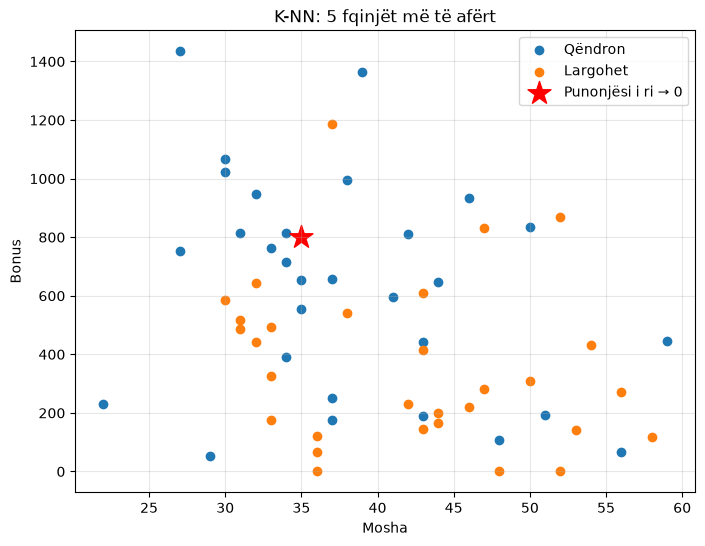

In [6]:
# Vizualizimi
plt.figure(figsize=(8, 6))

plt.scatter(
    X[y == 0]["Mosha"],
    X[y == 0]["Bonus"],
    label="Qëndron"
)

plt.scatter(
    X[y == 1]["Mosha"],
    X[y == 1]["Bonus"],
    label="Largohet"
)

# Punonjësi i ri
plt.scatter(
    35, 800,
    marker="*",
    s=300,
    color="red",
    label=f"Punonjësi i ri → {pred}"
)

plt.xlabel("Mosha")
plt.ylabel("Bonus")
plt.title("K-NN: 5 fqinjët më të afërt")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Kontroll i shpejtë
1. Çfarë ndodh nëse `k=1`? Pika e re kopjon fqinjin e vetëm më të afërt.
2. Po nëse `k` = të gjithë punonjësit? Çdo parashikim bëhet klasa e shumicës — e padobishme.
3. Pika e mirë është në mes — seksioni tjetër.



---
## 3 · Efekti i parametrit k

| k | Sjellja | Rreziku |
|---|---------|---------|
| **k = 3** | Shumë i ndjeshëm ndaj zhurmës lokale | Overfitting |
| **k = 5** | Fillim i fortë / default praktik | Zakonisht i balancuar |
| **k = 11** | Vendim i lëmuar / i zbehtë | Underfitting |

**Rregull i praktikës:** zgjidh **k tek** (shmang barazinë 50/50), nisu nga 5, pastaj krahaso me CV.



In [7]:
k_values = [1, 3, 5, 7, 11, 15, 21]

results = []

for k in k_values:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k))
    ])

    score = cross_val_score(
        model, df[FEATURES], df[TARGET],
        cv=5,
        scoring="f1"
    ).mean()

    results.append(score)

    print(f"k={k} → F1={score:.3f}")

# K më i mirë
best_k = k_values[np.argmax(results)]

print(f"\nK më i mirë = {best_k}")

k=1 → F1=0.719
k=3 → F1=0.750


k=5 → F1=0.762


k=7 → F1=0.784


k=11 → F1=0.773
k=15 → F1=0.774
k=21 → F1=0.757

K më i mirë = 7


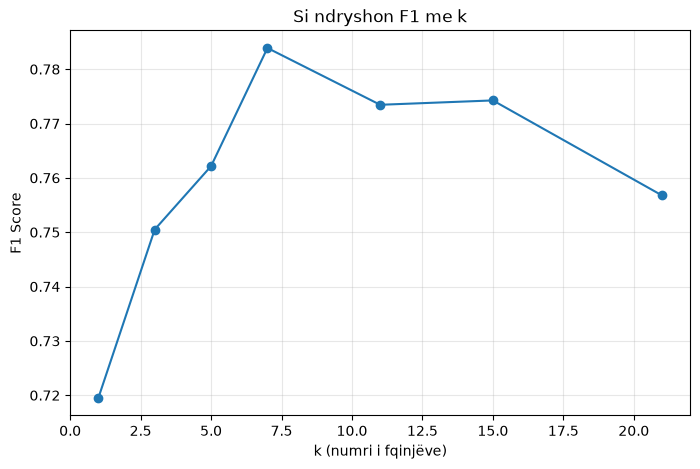

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, results, "o-")

plt.xlabel("k (numri i fqinjëve)")
plt.ylabel("F1 Score")
plt.title("Si ndryshon F1 me k")

plt.grid(alpha=0.3)
plt.show()

### Si ta lexojmë kurbën
- **k i vogël** → vendime zig-zag, variancë e lartë
- **k i madh** → vendimet bëhen "të zbehta", klasa e shumicës fillon të fitojë
- Përdor **CV F1**, jo një split të vetëm me fat, për të zgjedhur k
- Në *këtë* dataset kurba mund të mbetet e lartë edhe për k më të madh — në rregull. Beso numrat, jo një rregull fiks.



---
## 4 · StandardScaler — hap i detyrueshëm për K-NN

### Problemi

K-NN përdor distancën Euclidean. 

- `Mosha`: ~22–60
- `Bonus`: ~0–1400
- `Paga`: ~1600–6400

Pa scaling, **Paga / Bonus dominjnë** distancën. Mosha pothuajse zhduket.

### Zgjidhja

`StandardScaler` → çdo veçori ka mesatare ≈ 0 dhe std ≈ 1.
Pastaj çdo veçori "peshon" njësoj në distancë.



In [9]:
# Krahasojmë K-NN me dhe pa scaling — mbi të gjithë dataset-in
k = 5
X = df[FEATURES]
y = df[TARGET]

# Pa scaling
knn_raw = KNeighborsClassifier(n_neighbors=k)
f1_raw = cross_val_score(knn_raw, X, y, cv=5, scoring="f1").mean()

# Me scaling
knn_scaled = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=k))
])
f1_scaled = cross_val_score(knn_scaled, X, y, cv=5, scoring="f1").mean()

print(f"Pa scaling → F1 = {f1_raw:.3f}")
print(f"Me scaling → F1 = {f1_scaled:.3f}")

print(f"\nPërmirësimi: {(f1_scaled - f1_raw) * 100:.1f} pikë përqindje")


Pa scaling → F1 = 0.663


Me scaling → F1 = 0.762

Përmirësimi: 9.9 pikë përqindje


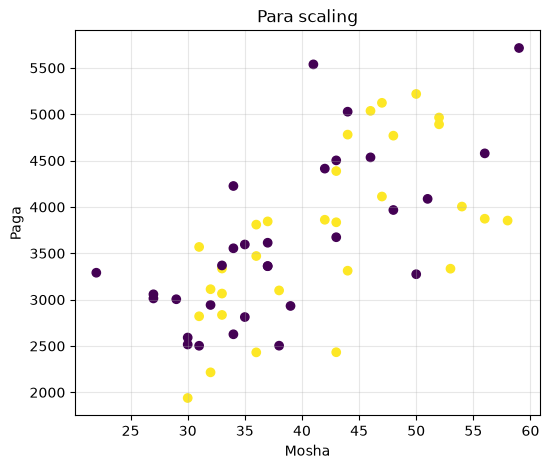

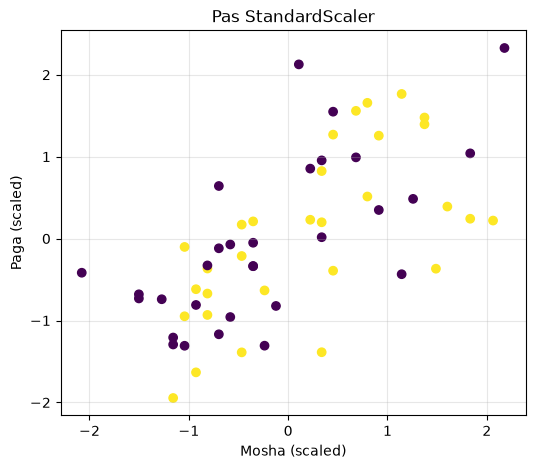

In [10]:
# Mosha vs Paga: para dhe pas scaling
X = demo[["Mosha", "Paga"]]
y = demo["churn"]
# Para scaling
plt.figure(figsize=(6, 5))

plt.scatter(
    X["Mosha"],
    X["Paga"],
    c=y
)

plt.xlabel("Mosha")
plt.ylabel("Paga")
plt.title("Para scaling")
plt.grid(alpha=0.3)

plt.show()


# Pas scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X[["Mosha", "Paga"]])

plt.figure(figsize=(6, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=y
)

plt.xlabel("Mosha (scaled)")
plt.ylabel("Paga (scaled)")
plt.title("Pas StandardScaler")
plt.grid(alpha=0.3)

plt.show()

### Rregulli

> Gjithmonë bëj scale para **K-NN** (dhe çdo modeli që përdor distancë).
>
> Bëji `fit` scaler-it **vetëm mbi train**, pastaj `transform` test — ose i mbështill të dyja në një `Pipeline`.



---
## 5 · Logistic Regression vs K-NN

I njëjti dataset, i njëjti CV=5, i njëjti metrikë F1 — modele të ndryshme.



In [11]:
# Krahasojmë Logistic Regression dhe K-NN

X = df[["Mosha", "Bonus", "vite_pune", "Paga"]]
y = df["churn"]

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "K-NN k=5 pa scaling": KNeighborsClassifier(n_neighbors=5),
    "K-NN k=3 me scaling": Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=3))
    ]),
    "K-NN k=5 me scaling": Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=5))
    ]),
    "K-NN k=11 me scaling": Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=11))
    ])
}

names = []
scores = []

for name, model in models.items():

    score = cross_val_score(
        model,
        X, y,
        cv=5,
        scoring="f1"
    ).mean()

    names.append(name)
    scores.append(score)

    print(f"{name} → F1 = {score:.3f}")

Logistic Regression → F1 = 0.827
K-NN k=5 pa scaling → F1 = 0.663


K-NN k=3 me scaling → F1 = 0.750
K-NN k=5 me scaling → F1 = 0.762
K-NN k=11 me scaling → F1 = 0.773


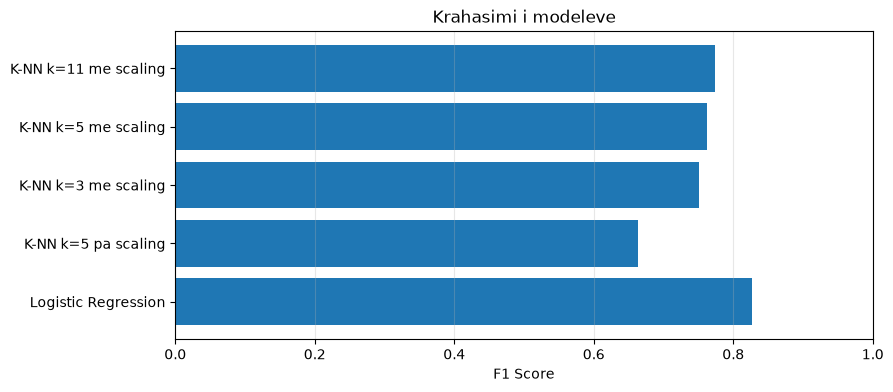

Modeli më i mirë: Logistic Regression
F1 = 0.827


In [12]:
# Vizualizimi
plt.figure(figsize=(9, 4))

plt.barh(names, scores)

plt.xlabel("F1 Score")
plt.title("Krahasimi i modeleve")
plt.xlim(0, 1)
plt.grid(axis="x", alpha=0.3)

plt.show()


# Modeli më i mirë
best_index = np.argmax(scores)

print(f"Modeli më i mirë: {names[best_index]}")
print(f"F1 = {scores[best_index]:.3f}")

### Kur ta zgjedh cilin?

| Prefero **Logistic Regression** kur… | Prefero **K-NN** kur… |
|--------------------------------------|------------------------|
| Do **koeficientë të interpretueshëm** | Kufiri i vendimit duket **i lakuar / lokal** |
| Do **probabilitete** të qarta | Dataset-i është **i vogël / i mesëm** |
| Klasat ndahen afërsisht **linearisht** | Ke aplikuar tashmë **StandardScaler** |
| Dataset-i është **i madh** (parashikim i shpejtë) | Je gati të bësh tuning të **k** |



## Ushtrim 1 — Punonjësi i ri

HR ju jep profilin e një punonjësi të ri. Me K-NN **të shkallëzuar** me `k=5`, të trajnuar mbi **training split**:

1. Bëji `fit` `StandardScaler` mbi `X_train`, pastaj `transform` train + test
2. Trajno `KNeighborsClassifier(n_neighbors=5)`
3. Parashiko churn për këtë person:

| Mosha | Rating | Bonus | vite_pune | Paga |
|------:|-------:|------:|----------:|-----:|
| 29 | 2.0 | 350 | 1.5 | 2800 |

4. Printo edhe `predict_proba` — sa e sigurt është vota?

**Bonus:** ndrysho `k` në 3 dhe 11. A ndryshon parashikimi?



## Ushtrim 2 — Historia e fqinjëve *(opsionale)*

Zgjidh **një** punonjës nga test set (`iloc[0]` mjafton).

1. Bëj scale të dhënave
2. Përdor `kneighbors` për të gjetur **5 fqinjët** më të afërt në train
3. Printo `Mosha`, `Bonus`, `Paga` dhe `churn` të atyre fqinjëve
4. A përputhet vota e shumicës me parashikimin e modelit? Me etiketën e vërtetë?



### Zgjidhja A


In [13]:
scaler_a = StandardScaler()
X_train_a = scaler_a.fit_transform(X_train)
X_test_a = scaler_a.transform(X_test)

knn_a = KNeighborsClassifier(n_neighbors=5)
knn_a.fit(X_train_a, y_train)

new_hire = pd.DataFrame([{
    "Mosha": 29, "Bonus": 350, "vite_pune": 1.5, "Paga": 2800
}])
new_s = scaler_a.transform(new_hire)

pred = knn_a.predict(new_s)[0]
proba = knn_a.predict_proba(new_s)[0]
print(f"Parashikimi: churn={pred}  →  {'Largohet' if pred == 1 else 'Qëndron'}")
print(f"Probabilitetet [Qëndron, Largohet]: {proba.round(3)}")

print("\nPo nëse ndryshon k?")
for k in [3, 5, 11]:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train_a, y_train)
    print(f"  k={k:>2} → churn={m.predict(new_s)[0]}  proba={m.predict_proba(new_s)[0].round(3)}")



Parashikimi: churn=1  →  Largohet
Probabilitetet [Qëndron, Largohet]: [0. 1.]

Po nëse ndryshon k?
  k= 3 → churn=1  proba=[0. 1.]
  k= 5 → churn=1  proba=[0. 1.]
  k=11 → churn=1  proba=[0.091 0.909]


### Zgjidhja D


In [14]:
scaler_d = StandardScaler()
X_train_d = scaler_d.fit_transform(X_train)
X_test_d = scaler_d.transform(X_test)

knn_d = KNeighborsClassifier(n_neighbors=5)
knn_d.fit(X_train_d, y_train)

i = 0  # punonjësi i parë në test
person = X_test_d[i:i+1]
pred = knn_d.predict(person)[0]
true = y_test.iloc[i]

dists, idxs = knn_d.kneighbors(person)
neighbors = X_train.iloc[idxs[0]].copy()
neighbors["churn"] = y_train.iloc[idxs[0]].values

print(f"Punonjësi në test: churn i vërtetë={true}  |  parashikimi i modelit={pred}")
print("\n5 fqinjët më të afërt në train:")
print(neighbors[["Mosha", "Bonus", "Paga", "churn"]].round(1))
print(f"\nVota e shumicës = {int(neighbors['churn'].mode()[0])}  (përputhet me parashikimin? {int(neighbors['churn'].mode()[0]) == pred})")



Punonjësi në test: churn i vërtetë=0  |  parashikimi i modelit=0

5 fqinjët më të afërt në train:
     Mosha  Bonus    Paga  churn
337     39  843.0  4834.4      0
347     42  812.0  4413.8      0
167     41  947.9  4715.8      0
256     46  932.2  4535.1      0
287     42  837.8  4557.2      1

Vota e shumicës = 0  (përputhet me parashikimin? True)
